# 🧭 4b. EDA multivariado y días sin venta

Este capítulo se agregó en la **segunda entrega** para responder a la retroalimentación de la primera: faltaba un análisis multivariado más completo (PCA, atípicos multivariados y agrupación de negocios) y estudiar los **días sin venta**, que concentran casi todo el error del modelo base (cap. 8).

La unidad de análisis es el **negocio** (cap. 1): se resume cada negocio en un **perfil** de variables y se analizan los 452 perfiles. Todo se calcula **solo con jul – ago** (dentro de train), como en el capítulo 4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.covariance import MinCovDet
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from comun import estilo, cargar_panel, PALETA, AZUL, NARANJA, VERDE, GRIS, DIAS, SEED
from datos import preparar, partir

estilo()
panel = cargar_panel()
jul_ago = panel[panel["fecha"] < "2026-09-01"].copy()
jul_ago["y_log"] = np.log1p(jul_ago["venta_total"].clip(lower=0))
print(f"{jul_ago['negocio'].nunique()} negocios, {len(jul_ago):,} negocio-días (jul – ago)")

448 negocios, 27,581 negocio-días (jul – ago)


## 🧱 4b.1 Perfil de cada negocio

Para cada negocio se calculan 11 variables que describen **cómo vende**, no cuánto vendió un día puntual:

| Variable | Qué mide |
|---|---|
| `nivel` | media de $\log(1 + \text{venta})$ en días con venta |
| `volatilidad` | desviación estándar de $\log(1 + \text{venta})$ en días con venta |
| `pct_sin_venta` | porcentaje de días activos sin venta |
| `finde` | venta media de sáb–dom sobre la de lun–vie (log del cociente) |
| `part_*` | participación de cada grupo de medios en la venta total |
| `n_fuentes` | número medio de fuentes (sistemas POS) por día |

In [2]:
medios = ["efectivo", "datafono", "rumbo", "mi_empresa", "credito_clientes", "otros"]
con_venta = jul_ago[jul_ago["venta_total"] > 0]
g = con_venta.groupby("negocio")
perfil = pd.DataFrame({
    "nivel": g["y_log"].mean(),
    "volatilidad": g["y_log"].std(),
    "pct_sin_venta": jul_ago.groupby("negocio")["sin_registro"].mean() * 100,
    "n_fuentes": jul_ago.groupby("negocio")["n_fuentes"].mean(),
})
finde = con_venta.assign(finde=con_venta["fecha"].dt.dayofweek >= 5).groupby(["negocio", "finde"])["venta_total"].mean().unstack()
perfil["finde"] = np.log(finde[True] / finde[False])
total = jul_ago.groupby("negocio")[[f"pm_{m}" for m in medios] + ["venta_total"]].sum()
for m in medios:
    perfil[f"part_{m}"] = total[f"pm_{m}"] / total["venta_total"]
perfil = perfil.dropna()
print(f"{len(perfil)} negocios con perfil completo")
perfil.describe().T

447 negocios con perfil completo


,count,mean,std,min,25%,50%,75%,max
nivel,447.00,15.51,2.02,9.39,14.68,15.47,17.21,19.13
volatilidad,447.00,0.31,0.21,0.08,0.18,0.25,0.36,1.82
pct_sin_venta,447.00,0.48,2.67,0.00,0.00,0.00,0.00,30.65
n_fuentes,447.00,1.06,0.24,0.69,1.00,1.00,1.00,2.00
finde,447.00,0.01,0.31,-4.23,-0.12,0.01,0.16,0.99
part_efectivo,447.00,0.65,0.25,0.00,0.46,0.59,0.91,1.00
part_datafono,447.00,0.26,0.20,0.00,0.06,0.30,0.40,0.86
part_rumbo,447.00,0.03,0.07,0.00,0.00,0.00,0.03,0.47
part_mi_empresa,447.00,0.01,0.02,0.00,0.00,0.00,0.01,0.22
part_credito_clientes,447.00,0.00,0.02,0.00,0.00,0.00,0.00,0.37


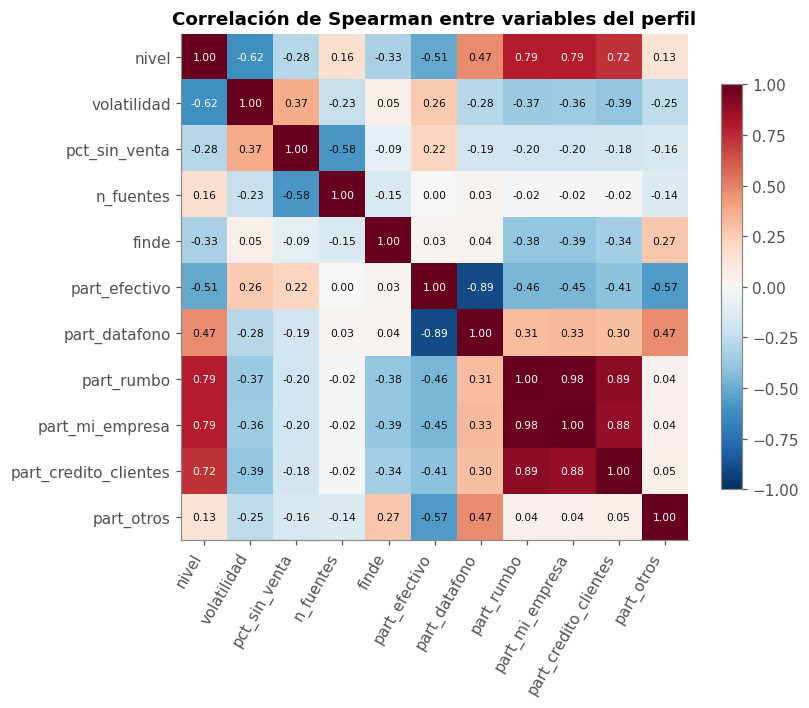

In [3]:
# correlaciones de Spearman entre las variables del perfil
corr = perfil.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación de Spearman entre variables del perfil")
plt.tight_layout()

## 📉 4b.2 Análisis de componentes principales (PCA)

El PCA busca las direcciones en las que los perfiles varían más. Como las variables están en escalas distintas (log, porcentajes, proporciones), se **estandarizan** antes (media 0, desviación 1), así que el PCA trabaja sobre la matriz de correlaciones.

,varianza (%),acumulada (%),autovalor
PC1,30.25,30.25,3.34
PC2,17.19,47.45,1.90
PC3,15.27,62.72,1.68
PC4,9.75,72.47,1.08
PC5,7.73,80.20,0.85


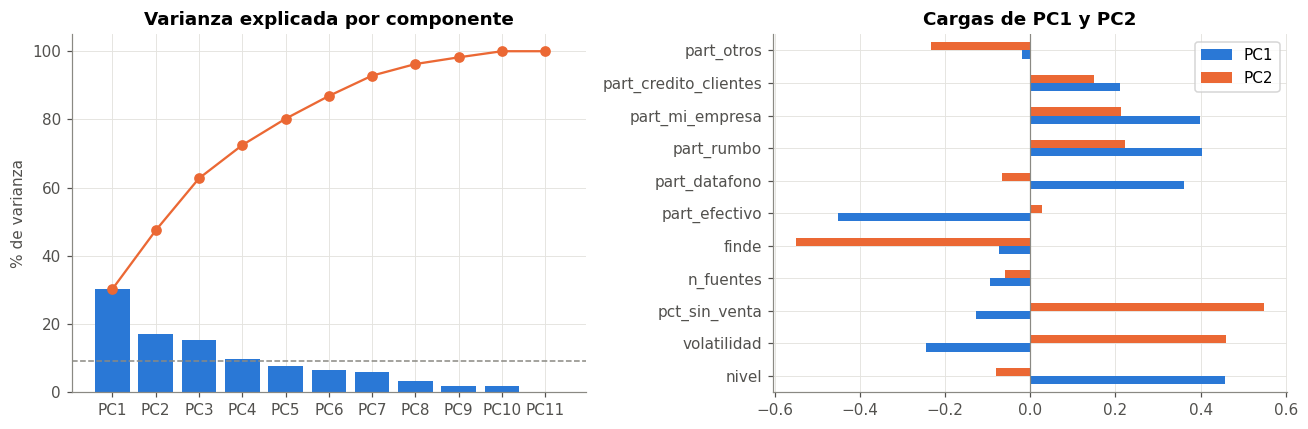

In [4]:
Z = StandardScaler().fit_transform(perfil)
pca = PCA(random_state=SEED).fit(Z)
var = pd.DataFrame({"varianza (%)": pca.explained_variance_ratio_ * 100,
                    "acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100,
                    "autovalor": pca.explained_variance_},
                   index=[f"PC{i + 1}" for i in range(len(pca.explained_variance_))])
cargas = pd.DataFrame(pca.components_[:3].T, index=perfil.columns, columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(var.index, var["varianza (%)"], color=AZUL)
ax[0].plot(var.index, var["acumulada (%)"], color=NARANJA, marker="o")
ax[0].axhline(100 / len(var), color=GRIS, ls="--", lw=1)
ax[0].set_ylabel("% de varianza"); ax[0].set_title("Varianza explicada por componente")
cargas[["PC1", "PC2"]].plot.barh(ax=ax[1], color=[AZUL, NARANJA])
ax[1].axvline(0, color=GRIS, lw=0.8); ax[1].set_title("Cargas de PC1 y PC2")
plt.tight_layout()
var.head(5).round(2)

In [5]:
cargas.round(2).sort_values("PC1")

,PC1,PC2,PC3
part_efectivo,-0.45,0.03,-0.40
volatilidad,-0.25,0.46,0.20
pct_sin_venta,-0.13,0.55,0.27
n_fuentes,-0.10,-0.06,-0.34
finde,-0.07,-0.55,-0.03
part_otros,-0.02,-0.23,0.52
part_credito_clientes,0.21,0.15,-0.16
part_datafono,0.36,-0.07,0.44
part_rumbo,0.40,0.22,-0.24
part_mi_empresa,0.40,0.21,-0.22


### Interpretación

- **PC1 (30 %) es el eje "tamaño y tipo de cliente"**: cargas positivas en `nivel` (0,46), `part_rumbo` y `part_mi_empresa` (0,40) y `part_datafono` (0,36), y negativa en `part_efectivo` (−0,45). Separa a los negocios grandes que venden a flotas con crédito Terpel (las EDS) de los pequeños que venden en efectivo. Es la misma relación mix–tamaño del capítulo 4 (ρ ≈ 0,79), ahora resumida en una sola dirección.
- **PC2 (17 %) es el eje "irregularidad"**: `pct_sin_venta` (0,55) y `volatilidad` (0,46) contra `finde` (−0,55). Son los negocios que tienen días sin venta, que son muy volátiles y que venden **menos** el fin de semana (cierran).
- **PC3 (15 %)** separa los negocios con mucho datáfono y "otros" medios (apps, bonos) de los que operan con varias fuentes.
- Hacen falta 5 componentes para el 80 % de la varianza. El perfil **no se reduce a una sola dimensión**: el tamaño explica solo un tercio de cómo se diferencian los negocios.

## 🧩 4b.3 Agrupación de negocios (k-means)

En el capítulo 1 la venta media por negocio salió **trimodal** y se planteó la hipótesis de que los grupos son los tipos de negocio (KCO, tienda, EDS). Aquí se agrupan los negocios por **todo su perfil** con k-means sobre las variables estandarizadas, y el número de grupos se elige con el **coeficiente de silueta** (qué tan cerca está cada negocio de su grupo frente al grupo vecino; va de −1 a 1).

In [6]:
sil = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    sil[k] = silhouette_score(Z, km.labels_)
# el k más chico cuya silueta queda a menos de 0,01 de la mejor (grupos más interpretables)
k_mejor = min(k for k in sil if sil[k] >= max(sil.values()) - 0.01)
km = KMeans(n_clusters=k_mejor, n_init=20, random_state=SEED).fit(Z)
# ordeno los grupos por nivel de venta para que el nombre sea estable
orden = perfil.groupby(km.labels_)["nivel"].mean().sort_values().index
perfil["grupo"] = pd.Series(km.labels_, index=perfil.index).map({g: f"G{i + 1}" for i, g in enumerate(orden)})
pd.Series(sil, name="silueta").round(3).to_frame().T

,2,3,4,5,6,7,8
silueta,0.29,0.27,0.29,0.34,0.34,0.34,0.33


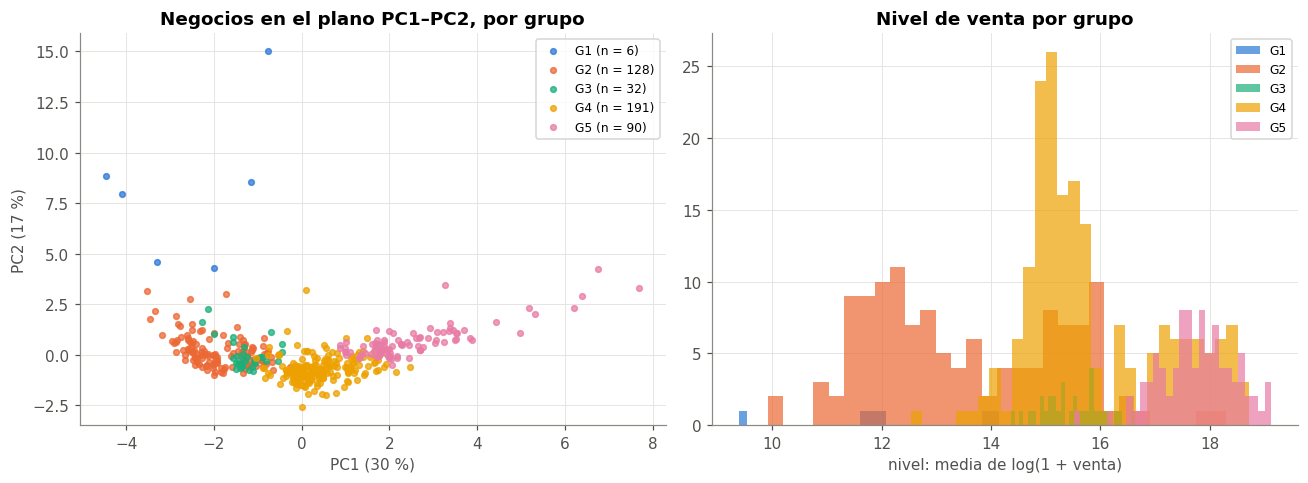

In [7]:
pcs = pca.transform(Z)[:, :2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, (gr, sub) in enumerate(perfil.groupby("grupo")):
    sel = (perfil["grupo"] == gr).values
    ax[0].scatter(pcs[sel, 0], pcs[sel, 1], s=14, alpha=0.75, color=PALETA[i], label=f"{gr} (n = {sel.sum()})")
    ax[1].hist(sub["nivel"], bins=30, alpha=0.7, color=PALETA[i], label=gr)
ax[0].set_xlabel(f"PC1 ({var.iloc[0, 0]:.0f} %)"); ax[0].set_ylabel(f"PC2 ({var.iloc[1, 0]:.0f} %)")
ax[0].set_title("Negocios en el plano PC1–PC2, por grupo"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("nivel: media de log(1 + venta)"); ax[1].set_title("Nivel de venta por grupo"); ax[1].legend(fontsize=8)
plt.tight_layout()

In [8]:
resumen = perfil.groupby("grupo").agg(negocios=("nivel", "size"), **{c: (c, "median") for c in perfil.columns if c != "grupo"})
resumen.insert(2, "venta típica (M COP)", np.expm1(resumen["nivel"]) / 1e6)
resumen.round(3).T

grupo,G1,G2,G3,G4,G5
negocios,6.00,128.00,32.00,191.00,90.00
nivel,11.88,13.21,15.48,15.47,17.77
venta típica (M COP),0.14,0.55,5.31,5.21,52.31
volatilidad,1.02,0.38,0.23,0.23,0.20
pct_sin_venta,20.65,0.00,0.00,0.00,0.00
n_fuentes,0.79,1.00,1.97,1.00,1.00
finde,-0.82,0.03,-0.16,0.09,-0.12
part_efectivo,0.83,1.00,0.90,0.53,0.45
part_datafono,0.14,0.00,0.10,0.39,0.35
part_rumbo,0.00,0.00,0.00,0.00,0.12


In [9]:
# ¿los grupos difieren de verdad? Kruskal-Wallis por variable (los grupos son negocios distintos,
# no medidas repetidas) con Holm
from statsmodels.stats.multitest import multipletests
filas = []
for c in perfil.columns.drop("grupo"):
    h, p = stats.kruskal(*[s[c] for _, s in perfil.groupby("grupo")])
    eps2 = h / (len(perfil) - 1)  # épsilon² de Kruskal-Wallis (tamaño del efecto)
    filas.append({"variable": c, "H": h, "p": p, "épsilon²": eps2})
kw = pd.DataFrame(filas)
kw["p Holm"] = multipletests(kw["p"], method="holm")[1]
kw.sort_values("épsilon²", ascending=False).round(4).set_index("variable")

,H,p,épsilon²,p Holm
variable,,,,
part_rumbo,326.26,0.00,0.73,0.00
part_mi_empresa,318.06,0.00,0.71,0.00
part_efectivo,304.33,0.00,0.68,0.00
part_datafono,295.33,0.00,0.66,0.00
n_fuentes,275.89,0.00,0.62,0.00
part_credito_clientes,256.47,0.00,0.58,0.00
nivel,237.66,0.00,0.53,0.00
part_otros,201.74,0.00,0.45,0.00
finde,124.21,0.00,0.28,0.00


### Interpretación

- La silueta es parecida entre k = 5 y k = 7 (0,34) y se elige **k = 5**, el más chico a 0,01 del máximo. Con k = 7 aparecen grupos de 1 negocio, que no son grupos sino atípicos. Una silueta de 0,34 indica una estructura **moderada**: los grupos existen, pero con zonas de transición.
- Los cinco grupos son interpretables:

| Grupo | n | Venta típica | Perfil | Tipo probable |
|---|---|---|---|---|
| G1 | 6 | 0,14 M | 21 % de días sin venta, muy volátil, cae el fin de semana | Negocios casi inactivos o que cierran fines de semana |
| G2 | 128 | 0,55 M | 100 % efectivo, ninguna otra forma de pago | **KCO** (kioscos de autoservicio) |
| G3 | 32 | 5,3 M | 2 fuentes POS por día, casi todo efectivo | Negocios con dos sistemas (por ejemplo tienda + GNV) |
| G4 | 191 | 5,2 M | ~50 % efectivo, ~40 % datáfono | **Tiendas de conveniencia** |
| G5 | 90 | 52 M | crédito Terpel (rumbo, mi empresa) ~16 % | **EDS** (estaciones de servicio) |

- La hipótesis del capítulo 1 se **confirma en parte**: los tres picos de venta (~0,1–0,5 M, ~5 M y ~50 M) corresponden a G2, G3/G4 y G5. Pero G3 y G4 venden lo mismo y se distinguen por **cómo** venden, no por cuánto.
- Kruskal-Wallis rechaza en las 11 variables (Holm). Los tamaños de efecto más grandes son los del mix de medios (ε² ≈ 0,7), por encima del propio nivel de venta (0,53).

## 🚩 4b.4 Atípicos multivariados

Un negocio puede ser normal en cada variable por separado y raro en la **combinación** (por ejemplo, mucha venta con casi todo en crédito propio). Se usan dos métodos:

1. **Distancia de Mahalanobis robusta**: la distancia de cada perfil al centro, teniendo en cuenta las correlaciones. El centro y la covarianza se estiman con el **MCD** (determinante de covarianza mínima), que usa el 75 % de negocios más "compacto" y así los propios atípicos no inflan la covarianza. Bajo normalidad la distancia al cuadrado sigue una $\chi^2_p$; se marca como atípico lo que pasa el percentil 97,5.
   Se aplica sobre las **5 primeras componentes del PCA** (80 % de la varianza): con las 11 variables originales la covarianza es singular, porque participaciones como `part_credito_clientes` valen 0 en casi todos los negocios.
2. **Isolation Forest**: aísla cada punto con cortes al azar; los atípicos se aíslan con menos cortes. No supone ninguna distribución.

In [10]:
# sobre las 5 primeras componentes (80 % de la varianza): con las 11 variables la covarianza es singular
X_perfil = pca.transform(Z)[:, :5]
corte = stats.chi2.ppf(0.975, X_perfil.shape[1])
sensib = {sf: (MinCovDet(support_fraction=sf, random_state=SEED).fit(X_perfil).mahalanobis(X_perfil) > corte).mean()
          for sf in [0.5, 0.75, 0.9]}
print("% de negocios sobre el corte χ² según la fracción del MCD:", {k: f"{v:.0%}" for k, v in sensib.items()})

iso = IsolationForest(n_estimators=300, contamination="auto", random_state=SEED).fit(X_perfil)
perfil["atipico_iso"] = iso.predict(X_perfil) == -1
# el corte χ² no sirve (ver texto): uso la distancia robusta solo para ordenar y marco
# tantos negocios como el Isolation Forest, para ver si los dos métodos coinciden
d2 = MinCovDet(support_fraction=0.75, random_state=SEED).fit(X_perfil).mahalanobis(X_perfil)
perfil["mahalanobis"] = np.sqrt(d2)
perfil["atipico_mcd"] = perfil["mahalanobis"].rank(ascending=False) <= perfil["atipico_iso"].sum()
print(f"Mahalanobis robusta (los más lejanos): {perfil['atipico_mcd'].sum()}")
print(f"Isolation Forest:    {perfil['atipico_iso'].sum()} atípicos ({perfil['atipico_iso'].mean():.1%})")
print(f"en ambos:            {(perfil['atipico_mcd'] & perfil['atipico_iso']).sum()}")
pd.crosstab(perfil["grupo"], [perfil["atipico_mcd"], perfil["atipico_iso"]], margins=True)

% de negocios sobre el corte χ² según la fracción del MCD: {0.5: '46%', 0.75: '29%', 0.9: '25%'}


Mahalanobis robusta (los más lejanos): 41
Isolation Forest:    41 atípicos (9.2%)
en ambos:            25


atipico_mcd False       True       All
atipico_iso False True False True     
grupo                                 
G1              0    0     0    6    6
G2            125    3     0    0  128
G3              9    4    12    7   32
G4            184    6     1    0  191
G5             72    3     3   12   90
All           390   16    16   25  447

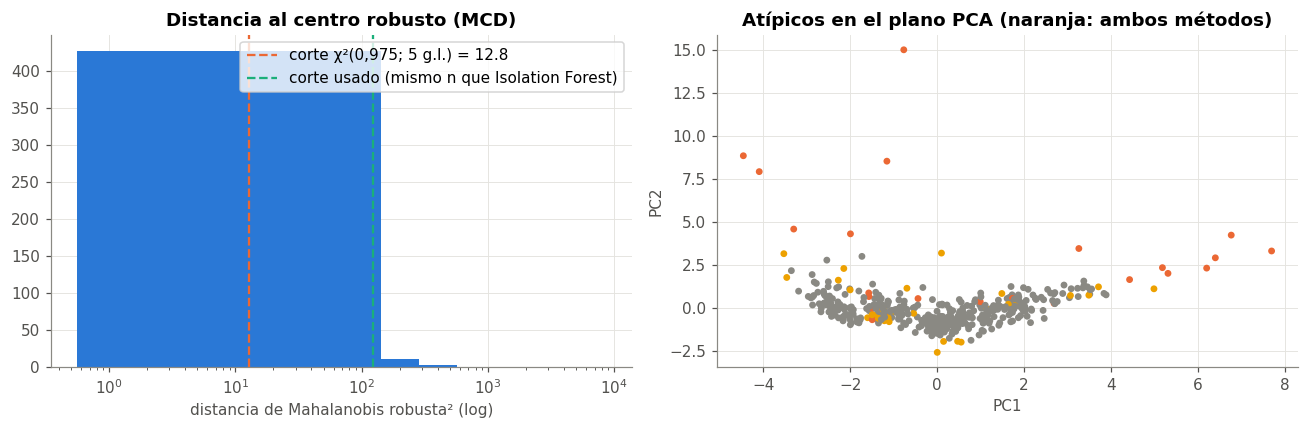

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(d2, bins=60, color=AZUL)
ax[0].axvline(corte, color=NARANJA, ls="--", label=f"corte χ²(0,975; {X_perfil.shape[1]} g.l.) = {corte:.1f}")
ax[0].axvline(np.sort(d2)[-perfil["atipico_iso"].sum()], color=VERDE, ls="--", label="corte usado (mismo n que Isolation Forest)")
ax[0].set_xscale("log"); ax[0].set_xlabel("distancia de Mahalanobis robusta² (log)")
ax[0].set_title("Distancia al centro robusto (MCD)"); ax[0].legend()
col = np.where(perfil["atipico_mcd"] & perfil["atipico_iso"], NARANJA, np.where(perfil["atipico_mcd"] | perfil["atipico_iso"], "#eda100", GRIS))
ax[1].scatter(pcs[:, 0], pcs[:, 1], s=12, c=col)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Atípicos en el plano PCA (naranja: ambos métodos)")
plt.tight_layout()

In [12]:
# qué tienen de raro los atípicos de ambos métodos: z robusta de cada variable frente a la mediana
ambos = perfil[perfil["atipico_mcd"] & perfil["atipico_iso"]].drop(columns=["grupo", "atipico_mcd", "atipico_iso"])
base = perfil.drop(columns=["grupo", "atipico_mcd", "atipico_iso", "mahalanobis"])
z_rob = (base - base.median()) / (stats.median_abs_deviation(base, scale="normal") + 1e-9)
z_rob.loc[ambos.index].abs().idxmax(axis=1).value_counts().rename("variable más extrema").to_frame()

,variable más extrema
part_rumbo,10
n_fuentes,7
pct_sin_venta,6
part_credito_clientes,2


### Interpretación

- **El corte χ² de la distancia de Mahalanobis no sirve aquí.** Supone que los perfiles son (aproximadamente) normales multivariados, alrededor de un solo centro. Pero los perfiles son una **mezcla de cinco grupos** y tienen masas de puntos en 0 (por ejemplo, ningún KCO usa crédito). Por eso el porcentaje de "atípicos" depende casi por completo de la fracción del MCD (46 %, 29 % o 25 %): el MCD se queda con el grupo más compacto y todo lo demás parece lejos. Se usa la distancia solo para **ordenar** los negocios.
- El **Isolation Forest** no supone ninguna distribución y marca **41 negocios (9 %)**. De los 41 negocios más lejanos según Mahalanobis, **25 coinciden** con el Isolation Forest, así que los dos métodos están razonablemente de acuerdo en el núcleo de atípicos.
- Los atípicos se concentran en **G1** (los 6), **G3** y **G5**. Lo que los hace raros es sobre todo `part_rumbo` (EDS con mucho más crédito de flotas que las demás), `n_fuentes` y `pct_sin_venta`.
- **Decisión: no se elimina ningún negocio.** Son negocios reales con un perfil distinto, no errores de datos (los errores ya se limpiaron en el capítulo 2). Como en el capítulo 1, se describen y se tienen en cuenta al interpretar el error: los negocios de G1 son los candidatos a los días sin venta.

## 🕳️ 4b.5 Días sin venta y caídas fuertes

En el capítulo 8 los días sin venta fueron el 0,4 % de test pero el **71 % del error cuadrático en log**. Aquí se estudia **quién** tiene esos días, **cuándo** y si se pueden **anticipar** con lo que se sabe el día anterior. Se amplía la mirada a las **caídas fuertes**: días con venta menor al 50 % de la mediana de los 7 días anteriores, que incluyen los ceros. Este será el objetivo de la tarea de **clasificación** (cap. 9).

In [13]:
d = preparar(panel)
train, test = partir(d)
tr = train.copy()
tr["cero"] = (tr["venta_total"] <= 0).astype(int)
print(f"train: {len(tr):,} negocio-días con historia de 14 días")
print(f"  días sin venta: {tr['cero'].sum()} ({tr['cero'].mean():.2%}) en {tr.loc[tr['cero'] == 1, 'negocio'].nunique()} negocios")
print(f"  caídas fuertes: {tr['caida'].sum()} ({tr['caida'].mean():.2%}) en {tr.loc[tr['caida'] == 1, 'negocio'].nunique()} negocios")
print(f"  de las caídas, son días sin venta: {tr.loc[tr['caida'] == 1, 'cero'].mean():.1%}")
print(f"test: caídas fuertes {test['caida'].sum()} ({test['caida'].mean():.2%})")

train: 22,205 negocio-días con historia de 14 días
  días sin venta: 126 (0.57%) en 37 negocios
  caídas fuertes: 818 (3.68%) en 224 negocios
  de las caídas, son días sin venta: 12.6%
test: caídas fuertes 288 (3.10%)


,cero,caida
grupo,,
G1,20.68,27.80
G2,0.52,6.62
G3,0.19,3.35
G4,0.15,1.57
G5,0.02,2.24


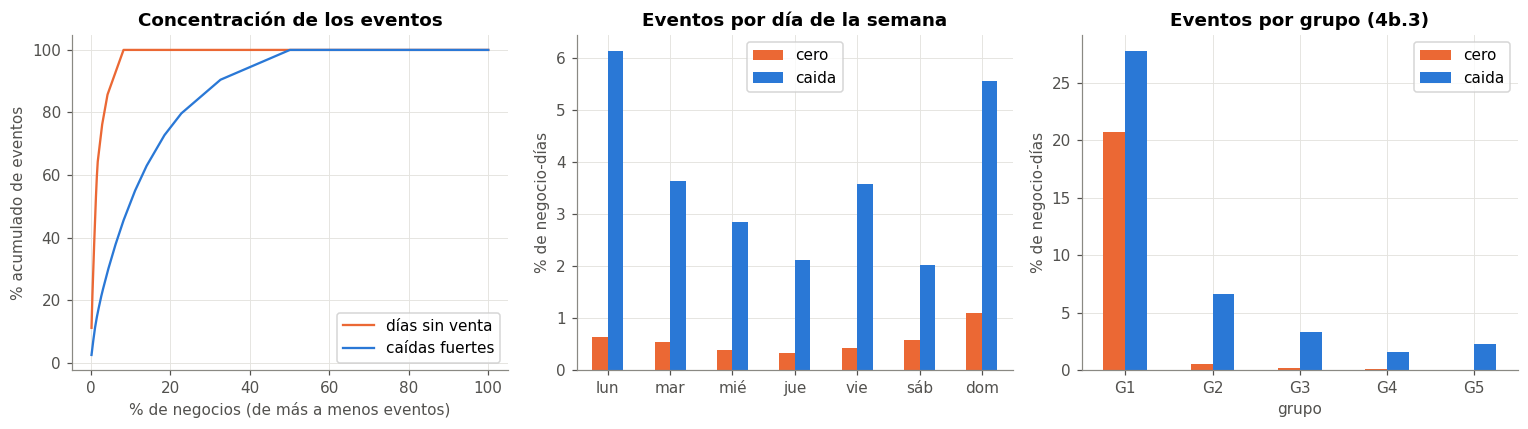

In [14]:
# concentración: ¿pocos negocios tienen casi todos los ceros/caídas?
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for col, color, nombre in [("cero", NARANJA, "días sin venta"), ("caida", AZUL, "caídas fuertes")]:
    por_neg = tr.groupby("negocio")[col].sum().sort_values(ascending=False)
    acum = por_neg.cumsum() / por_neg.sum() * 100
    ax[0].plot(np.arange(1, len(acum) + 1) / len(acum) * 100, acum.values, color=color, label=nombre)
ax[0].set_xlabel("% de negocios (de más a menos eventos)"); ax[0].set_ylabel("% acumulado de eventos")
ax[0].set_title("Concentración de los eventos"); ax[0].legend()

por_dia = tr.groupby(tr["fecha"].dt.dayofweek)[["cero", "caida"]].mean() * 100
por_dia.index = DIAS
por_dia.plot.bar(ax=ax[1], color=[NARANJA, AZUL], rot=0)
ax[1].set_ylabel("% de negocio-días"); ax[1].set_title("Eventos por día de la semana")

# por grupo de negocio
tr_g = tr.merge(perfil[["grupo"]], left_on="negocio", right_index=True, how="left")
por_grupo = tr_g.groupby("grupo")[["cero", "caida"]].mean() * 100
por_grupo.plot.bar(ax=ax[2], color=[NARANJA, AZUL], rot=0)
ax[2].set_ylabel("% de negocio-días"); ax[2].set_title("Eventos por grupo (4b.3)")
plt.tight_layout()
por_grupo.round(2)

In [15]:
# ¿se puede anticipar? tasa de caída según lo que se sabía el día anterior
tr["ayer_cero"] = (tr["lag1"] == 0).astype(int)
tabla = pd.DataFrame({
    "días sin venta en la última semana = 0": tr.loc[tr["dias_sin_venta7"] == 0, "caida"].mean(),
    "días sin venta en la última semana ≥ 1": tr.loc[tr["dias_sin_venta7"] >= 1, "caida"].mean(),
    "ayer sin venta": tr.loc[tr["ayer_cero"] == 1, "caida"].mean(),
    "ayer con venta": tr.loc[tr["ayer_cero"] == 0, "caida"].mean(),
    "festivo": tr.loc[tr["festivo"] == 1, "caida"].mean(),
    "no festivo": tr.loc[tr["festivo"] == 0, "caida"].mean(),
}, index=["P(caída)"]).T * 100
tabla["casos"] = [ (tr["dias_sin_venta7"] == 0).sum(), (tr["dias_sin_venta7"] >= 1).sum(),
                   tr["ayer_cero"].sum(), (1 - tr["ayer_cero"]).sum(), tr["festivo"].sum(), (1 - tr["festivo"]).sum()]
tabla.round(2)

,P(caída),casos
días sin venta en la última semana = 0,3.26,21765
días sin venta en la última semana ≥ 1,24.55,440
ayer sin venta,40.94,127
ayer con venta,3.47,22078
festivo,12.09,1332
no festivo,3.15,20873


In [16]:
# rachas: cuántos días seguidos dura una racha de días sin venta
rachas = []
for neg, s in panel.sort_values(["negocio", "fecha"]).groupby("negocio")["sin_registro"]:
    v = s.to_numpy()
    largo = 0
    for x in v:
        if x:
            largo += 1
        elif largo:
            rachas.append(largo); largo = 0
    if largo:
        rachas.append(largo)
rachas = pd.Series(rachas)
print(f"{len(rachas)} rachas sin venta; largo mediano {rachas.median():.0f} días, máximo {rachas.max()}")
rachas.value_counts().sort_index().head(10).rename("rachas").to_frame().T

100 rachas sin venta; largo mediano 1 días, máximo 19


,1,2,3,4,6,10,19
rachas,59,24,9,3,2,2,1


In [17]:
# volatilidad y probabilidad de caída del negocio en train: ¿los negocios irregulares son los que caen?
tasa = tr.groupby("negocio")["caida"].mean().rename("tasa_caida")
m = perfil.join(tasa, how="inner")
rho = m[["nivel", "volatilidad", "pct_sin_venta", "finde", "part_efectivo", "part_rumbo"]].corrwith(m["tasa_caida"], method="spearman")
rho.rename("Spearman con la tasa de caídas del negocio").round(3).to_frame()

,Spearman con la tasa de caídas del negocio
nivel,-0.39
volatilidad,0.74
pct_sin_venta,0.40
finde,-0.17
part_efectivo,0.33
part_rumbo,-0.14


### Interpretación

- Los **días sin venta** son el 0,57 % de train y están en solo **37 negocios** (8 %). La **caída fuerte** (venta < 50 % de la mediana de la semana anterior) es 6 veces más frecuente (3,7 %, 818 casos en 224 negocios) e incluye los ceros: el 12,6 % de las caídas son días sin venta.
- **Por grupo**: G1 tiene 21 % de días sin venta y 28 % de caídas; en G2 (KCO) las caídas son 6,6 %; en las EDS (G5), 1,3 %. La irregularidad es un rasgo del negocio: la tasa de caídas de cada negocio se correlaciona con su **volatilidad** (ρ = 0,74) y con su nivel (ρ = −0,39).
- **Sí se pueden anticipar en parte** con información del día anterior:
  - si el negocio tuvo al menos un día sin venta en la última semana, la probabilidad de caída sube de 3,3 % a **24,6 %**;
  - si ayer no vendió, llega a **40,9 %**: los días sin venta vienen en **rachas** (de las 100 rachas, 41 duran 2 días o más; la más larga, 19);
  - los **festivos** cuadruplican la probabilidad (12,1 % contra 3,2 %).
- Esto justifica dos decisiones de la entrega 2:
  1. **Tarea de clasificación**: predecir la caída fuerte del día siguiente. Es un evento desbalanceado (3,7 % de positivos), útil para el negocio como alerta y con señal en las variables, así que tiene sentido comparar técnicas de balanceo (cap. 9).
  2. **Modelo en dos partes** para la regresión (cap. 12): primero la probabilidad de caída y luego el monto, como sugirió la retroalimentación.

```{note}
**Resumen del capítulo (hallazgo → decisión)**

| Hallazgo | Decisión |
|---|---|
| El perfil necesita 5 componentes para el 80 % de la varianza; PC1 = tamaño + crédito, PC2 = irregularidad | Se mantienen las variables de nivel y de mix por separado en el modelo |
| 5 grupos de negocios (KCO, tiendas, EDS, dos fuentes, casi inactivos) | Se usan para leer los errores y los SHAP (cap. 12–14). No se entrenan modelos por grupo: los árboles pueden aprender esas interacciones |
| Los perfiles no son elípticos: el corte χ² de Mahalanobis no es válido | Atípicos con Isolation Forest (41 negocios); no se elimina ninguno |
| Caídas y ceros concentrados en negocios irregulares, en rachas y en festivos | Objetivo de clasificación = caída fuerte; modelo en dos partes en regresión |
```